# Wikidata12K

In [3]:
import pandas as pd
import json
from collections import defaultdict
import requests
from tqdm import tqdm
import time

# ================== CONFIG ==================
FILE_PATH = r"D:\Proposal\Temporal Reasoning\TKG\HyperSAT-main\data\wikidata12k\all.json"
LANGUAGES = ["en", "fr", "de", "es", "it", "ru", "zh"]
MAX_QIDS_TO_CHECK = 2000          # Smaller for reliability
# ===========================================

print("Loading dataset...")
entities = set()
with open(FILE_PATH, 'r', encoding='utf-8') as f:
    for line in f:
        if line.strip():
            data = json.loads(line)
            entities.add(data.get('subject'))
            entities.add(data.get('object'))

print(f"Total unique QIDs: {len(entities)}")

sample_qids = list(entities)[:MAX_QIDS_TO_CHECK]

def get_label_coverage(qids, languages=LANGUAGES):
    coverage = defaultdict(set)
    chunks = [qids[i:i+50] for i in range(0, len(qids), 50)]   # Smaller chunks
    
    for chunk in tqdm(chunks, desc="Fetching labels"):
        ids_str = "|".join(chunk)
        url = "https://www.wikidata.org/w/api.php"
        params = {
            "action": "wbgetentities",
            "ids": ids_str,
            "props": "labels",
            "languages": "|".join(languages),
            "format": "json"
        }
        headers = {'User-Agent': 'LabelCoverageAnalysis/1.0 (your.email@example.com)'}
        
        try:
            resp = requests.get(url, params=params, headers=headers, timeout=20)
            if resp.status_code == 200:
                data = resp.json()
                if "entities" in data:
                    for qid in chunk:
                        entity = data["entities"].get(qid)
                        if entity and "labels" in entity:
                            for lang in languages:
                                if lang in entity["labels"]:
                                    coverage[lang].add(qid)
        except Exception as e:
            print(f"Error: {e}")
        time.sleep(0.8)
    
    return coverage

print("Analyzing label coverage...")
coverage = get_label_coverage(sample_qids)

# Results
print("\n=== Label Coverage Analysis ===")
print(f"Sample size: {len(sample_qids)} QIDs\n")

data = []
for lang in LANGUAGES:
    count = len(coverage[lang])
    percentage = (count / len(sample_qids) * 100) if sample_qids else 0
    data.append({
        "Language": lang.upper(),
        "Entities with Label": count,
        "Coverage %": round(percentage, 2)
    })

df = pd.DataFrame(data)
print(df.sort_values("Coverage %", ascending=False).to_string(index=False))

print("\nRecommended pairs will be based on top coverage languages.")

Loading dataset...
Total unique QIDs: 12554
Analyzing label coverage...


Fetching labels: 100%|█████████████████████████████████████████████████████████████████| 40/40 [01:29<00:00,  2.24s/it]


=== Label Coverage Analysis ===
Sample size: 2000 QIDs

Language  Entities with Label  Coverage %
      EN                 1994       99.70
      FR                 1906       95.30
      DE                 1846       92.30
      ES                 1791       89.55
      IT                 1686       84.30
      RU                 1636       81.80
      ZH                 1505       75.25

Recommended pairs will be based on top coverage languages.


# Label Coverage

In [5]:
import json, requests, time, pandas as pd
from collections import defaultdict
from itertools import combinations

FILE_PATH = r"D:\Proposal\Temporal Reasoning\TKG\HyperSAT-main\data\wikidata12k\all.json"
# Save path — adjust to your Drive path
SAVE_PATH = r"D:\Proposal\Temporal Reasoning\TKG\HyperSAT-main\data\wikidata12k\wikidata12k_labels.tsv"

# Load QIDs
qids = set()
with open(FILE_PATH) as f:
    for line in f:
        row = json.loads(line.strip())
        qids.add(row['subject'])
        qids.add(row['object'])
qids = list(qids)
print(f"Total entities: {len(qids)}")

# Fetch labels from Wikidata
def fetch_batch(batch):
    url = "https://www.wikidata.org/w/api.php"
    params = {"action":"wbgetentities","ids":"|".join(batch),
              "props":"labels","format":"json"}
    headers = {"User-Agent": "CrossLingualTKG/1.0 (PhD research)"}
    for attempt in range(3):
        try:
            r = requests.get(url, params=params, headers=headers, timeout=30)
            return r.json().get("entities", {})
        except:
            time.sleep(5)
    return {}



all_labels = {}  # qid → {lang: label}
for i in range(0, len(qids), 50):
    batch = qids[i:i+50]
    entities = fetch_batch(batch)
    for qid, data in entities.items():
        all_labels[qid] = {
            lang: info['value']
            for lang, info in data.get('labels', {}).items()
        }
    if i % 500 == 0:
        print(f"  {i}/{len(qids)}...", end="\r")
    time.sleep(0.5)

# Save labels
pd.DataFrame([
    {"entity": qid, "lang": lang, "label": label}
    for qid, lang_labels in all_labels.items()
    for lang, label in lang_labels.items()
]).to_csv(SAVE_PATH, sep="\t", index=False)
print(f"Labels saved to {SAVE_PATH}")

# ── Coverage per language ──
lang_entity_count = defaultdict(int)
for qid, lang_labels in all_labels.items():
    for lang in lang_labels:
        lang_entity_count[lang] += 1

df_cov = pd.DataFrame([
    {"lang": lang,
     "entities": count,
     "coverage_%": round(100 * count / len(qids), 1)}
    for lang, count in lang_entity_count.items()
]).sort_values("entities", ascending=False)

print("\nTop 20 languages by coverage:")
print(df_cov.head(20).to_string(index=False))

# ── Pairwise overlap for top 15 languages ──
# TOP_N = 15
# top_langs = df_cov.head(TOP_N)['lang'].tolist()

# lang_entities = {
#     lang: {qid for qid, labels in all_labels.items() if lang in labels}
#     for lang in top_langs
# }

# # Load quadruples to measure subgraph sizes
# quads = []
# with open("all.json") as f:
#     for line in f:
#         row = json.loads(line.strip())
#         quads.append((row['subject'], row['relation'],
#                       row['object'], row['begin'], row['end']))

# import pandas as pd
# df_quad = pd.DataFrame(quads, columns=['head','relation','tail','begin','end'])

# print(f"\n{'LangA':6s} {'LangB':6s} {'|A∩B|':>8s} {'KG_A quads':>12s} "
#       f"{'KG_B quads':>12s} {'viable?':>8s}")

# for lang_a, lang_b in combinations(top_langs, 2):
#     ents_a = lang_entities[lang_a]
#     ents_b = lang_entities[lang_b]
#     both = ents_a & ents_b

#     mask_a = df_quad['head'].isin(ents_a) & df_quad['tail'].isin(ents_a)
#     mask_b = df_quad['head'].isin(ents_b) & df_quad['tail'].isin(ents_b)
#     qa = mask_a.sum()
#     qb = mask_b.sum()

#     viable = "✅" if len(both) >= 1000 and qa >= 5000 and qb >= 5000 else "⚠️"
#     print(f"{lang_a:6s} {lang_b:6s} {len(both):>8,} {qa:>12,} {qb:>12,} {viable:>8s}")

Total entities: 12554
Labels saved to D:\Proposal\Temporal Reasoning\TKG\HyperSAT-main\data\wikidata12k\wikidata12k_labels.tsv

Top 20 languages by coverage:
lang  entities  coverage_%
  en     10502        83.7
  fr     10133        80.7
  de      9814        78.2
  ca      9599        76.5
  es      9569        76.2
  nl      9464        75.4
  sv      9162        73.0
  it      9071        72.3
  ru      8769        69.9
  nb      8380        66.8
  pt      8294        66.1
  zh      8071        64.3
  pl      7915        63.0
  da      7888        62.8
  sl      7422        59.1
  ja      7418        59.1
  cs      7329        58.4
  ar      7277        58.0
  hu      7238        57.7
  uk      7081        56.4


FileNotFoundError: [Errno 2] No such file or directory: 'all.json'

In [6]:
TOP_N = 15
top_langs = df_cov.head(TOP_N)['lang'].tolist()

lang_entities = {
    lang: {qid for qid, labels in all_labels.items() if lang in labels}
    for lang in top_langs
}

# Load quadruples to measure subgraph sizes
quads = []
with open(FILE_PATH) as f:
    for line in f:
        row = json.loads(line.strip())
        quads.append((row['subject'], row['relation'],
                      row['object'], row['begin'], row['end']))

import pandas as pd
df_quad = pd.DataFrame(quads, columns=['head','relation','tail','begin','end'])

print(f"\n{'LangA':6s} {'LangB':6s} {'|A∩B|':>8s} {'KG_A quads':>12s} "
      f"{'KG_B quads':>12s} {'viable?':>8s}")

for lang_a, lang_b in combinations(top_langs, 2):
    ents_a = lang_entities[lang_a]
    ents_b = lang_entities[lang_b]
    both = ents_a & ents_b

    mask_a = df_quad['head'].isin(ents_a) & df_quad['tail'].isin(ents_a)
    mask_b = df_quad['head'].isin(ents_b) & df_quad['tail'].isin(ents_b)
    qa = mask_a.sum()
    qb = mask_b.sum()

    viable = "✅" if len(both) >= 1000 and qa >= 5000 and qb >= 5000 else "⚠️"
    print(f"{lang_a:6s} {lang_b:6s} {len(both):>8,} {qa:>12,} {qb:>12,} {viable:>8s}")


LangA  LangB     |A∩B|   KG_A quads   KG_B quads  viable?
en     fr       10,120       28,771       27,430        ✅
en     de        9,802       28,771       25,930        ✅
en     ca        9,587       28,771       25,938        ✅
en     es        9,560       28,771       25,688        ✅
en     nl        9,457       28,771       24,976        ✅
en     sv        9,147       28,771       22,825        ✅
en     it        9,058       28,771       23,442        ✅
en     ru        8,728       28,771       22,098        ✅
en     nb        8,368       28,771       19,488        ✅
en     pt        8,288       28,771       20,392        ✅
en     zh        8,044       28,771       19,657        ✅
en     pl        7,907       28,771       18,957        ✅
en     da        7,880       28,771       18,281        ✅
en     sl        7,413       28,771       16,519        ✅
fr     de        9,640       27,430       25,930        ✅
fr     ca        9,379       27,430       25,938        ✅
fr     es    

In [8]:
df_cov.shape

(500, 3)

In [11]:

print(df_cov.tail(20).to_string(index=False))

    lang  entities  coverage_%
     agq         2         0.0
     bqi         2         0.0
     ruq         2         0.0
     nyn         2         0.0
     yrl         2         0.0
     nod         2         0.0
     shy         1         0.0
kbd-cyrl         1         0.0
shi-tfng         1         0.0
ruq-cyrl         1         0.0
     tzm         1         0.0
 ks-deva         1         0.0
wuu-hant         1         0.0
bug-bugi         1         0.0
     khw         1         0.0
     kai         1         0.0
isv-latn         1         0.0
 uz-latn         1         0.0
     aeb         1         0.0
     kaj         1         0.0


In [25]:
TOP_N = 15
top_langs = ['fa', 'en']

lang_entities = {
    lang: {qid for qid, labels in all_labels.items() if lang in labels}
    for lang in top_langs
}

# Load quadruples to measure subgraph sizes
quads = []
with open(FILE_PATH) as f:
    for line in f:
        row = json.loads(line.strip())
        quads.append((row['subject'], row['relation'],
                      row['object'], row['begin'], row['end']))

import pandas as pd
df_quad = pd.DataFrame(quads, columns=['head','relation','tail','begin','end'])

print(f"\n{'LangA':6s} {'LangB':6s} {'|A∩B|':>8s} {'KG_A quads':>12s} "
      f"{'KG_B quads':>12s} {'viable?':>8s}")

for lang_a, lang_b in combinations(top_langs, 2):
    ents_a = lang_entities[lang_a]
    ents_b = lang_entities[lang_b]
    both = ents_a & ents_b

    mask_a = df_quad['head'].isin(ents_a) & df_quad['tail'].isin(ents_a)
    mask_b = df_quad['head'].isin(ents_b) & df_quad['tail'].isin(ents_b)
    qa = mask_a.sum()
    qb = mask_b.sum()

    viable = "✅" if len(both) >= 1000 and qa >= 5000 and qb >= 5000 else "⚠️"
    print(f"{lang_a:6s} {lang_b:6s} {len(both):>8,} {qa:>12,} {qb:>12,} {viable:>8s}")


LangA  LangB     |A∩B|   KG_A quads   KG_B quads  viable?
fa     en        6,098       14,285       28,771        ✅


In [24]:
df.to_csv('coverage.csv', index=False)

# Creating Cross-lingual TKG from wikidata12K

In [ ]:
import json, os, requests, time
import pandas as pd
import numpy as np
from collections import defaultdict

# ============================================================
# CONFIG
# ============================================================
JSON_PATH    = r"D:\Proposal\Temporal Reasoning\TKG\HyperSAT-main\data\wikidata12k\all.json"
OUTPUT_DIR   = "wikidata12k_crosslingual"
LABELS_CACHE = "wikidata12k_labels.tsv"

# LANG_PAIRS = [
#     ("en", "fr"),
#     ("en", "de"),
#     ("en", "zh"),
#     ("en", "ru"),
# ]

LANG_PAIRS = [
    ("en", "fr"),
    ("en", "fa"),
    ("en", "zh"),
    ("en", "ja"),
]

RANDOM_SEED = 42
os.makedirs(OUTPUT_DIR, exist_ok=True)

RELATION_LABELS = {
    "P6":    "head of government",      "P17":   "country",
    "P26":   "spouse",                  "P27":   "country of citizenship",
    "P31":   "instance of",             "P39":   "position held",
    "P54":   "member of sports team",   "P69":   "educated at",
    "P102":  "member of political party","P108":  "employer",
    "P131":  "located in administrative entity",
    "P150":  "contains administrative territorial entity",
    "P166":  "award received",          "P190":  "twinned administrative body",
    "P463":  "member of",               "P512":  "academic degree",
    "P551":  "residence",               "P579":  "IPC sports discipline code",
    "P793":  "significant event",       "P1346": "winner",
    "P1376": "capital of",              "P1411": "nominated for",
    "P1435": "heritage designation",    "P2962": "title of chess person",
}

# ============================================================
# Step 1: Load quadruples
# ============================================================
print("Step 1: Loading quadruples...")
quads = []
with open(JSON_PATH) as f:
    for line in f:
        row = json.loads(line.strip())
        quads.append({
            "head":     row['subject'],
            "relation": row['relation'],
            "tail":     row['object'],
            "begin":    row['begin'][0] if row['begin'] else "",
            "end":      row['end'][0]   if row['end']   else ""
        })
df_quad = pd.DataFrame(quads)
all_qids = list(set(df_quad['head']) | set(df_quad['tail']))
print(f"  {len(df_quad):,} quadruples | {len(all_qids):,} unique entities")

# ============================================================
# Step 2: Fetch multilingual labels
# Two methods tried in order:
#   A) wbgetentities API  (batch of 50, faster)
#   B) EntityData REST API (one by one, slower but more reliable)
# ============================================================

# ── Method A: batch wbgetentities ──
def fetch_batch_method_a(qids_batch, retries=3):
    url = "https://www.wikidata.org/w/api.php"
    params = {
        "action": "wbgetentities",
        "ids":    "|".join(qids_batch),
        "props":  "labels",
        "format": "json"
    }
    headers = {"User-Agent": "CrossLingualTKG/1.0 (PhD research)"}
    for attempt in range(retries):
        try:
            r = requests.get(url, params=params, headers=headers, timeout=60)
            if r.status_code == 429:
                wait = 30 * (attempt + 1)
                print(f"\n  Rate limited — waiting {wait}s...")
                time.sleep(wait)
                continue
            if r.status_code != 200 or not r.text.strip():
                time.sleep(10 * (attempt + 1))
                continue
            return r.json().get("entities", {})
        except Exception:
            time.sleep(10 * (attempt + 1))
    return None   # None signals "method A failed for this batch"

# ── Method B: one QID at a time via EntityData REST ──
def fetch_one_method_b(qid, retries=3):
    url = f"https://www.wikidata.org/wiki/Special:EntityData/{qid}.json"
    headers = {"User-Agent": "CrossLingualTKG/1.0 (PhD research)"}
    for attempt in range(retries):
        try:
            r = requests.get(url, headers=headers, timeout=30)
            if r.status_code == 429:
                time.sleep(30 * (attempt + 1))
                continue
            if r.status_code != 200 or not r.text.strip():
                time.sleep(5 * (attempt + 1))
                continue
            data = r.json()
            return data.get("entities", {}).get(qid, {}).get("labels", {})
        except Exception:
            time.sleep(5 * (attempt + 1))
    return {}

# ── Test which method works ──
def test_api():
    print("\n  Testing Method A (batch)...")
    result = fetch_batch_method_a(["Q76"])
    if result is not None and "Q76" in result:
        en = result["Q76"].get("labels", {}).get("en", {}).get("value", "")
        if en:
            print(f"  ✅ Method A works. Q76 EN label: {en}")
            return "A"
        
    print("  Method A failed. Testing Method B (REST)...")
    labels = fetch_one_method_b("Q76")
    if labels:
        en = labels.get("en", {}).get("value", "")
        print(f"  ✅ Method B works. Q76 EN label: {en}")
        return "B"
    
    print("  ❌ Both methods failed.")
    return None

# ── Main label fetcher ──
def fetch_all_labels(qids, method, batch_size=50):
    all_labels = {}
    
    if method == "A":
        for i in range(0, len(qids), batch_size):
            batch = qids[i:i+batch_size]
            result = fetch_batch_method_a(batch)
            
            if result is None:
                # Fallback to method B for this batch
                for qid in batch:
                    labels = fetch_one_method_b(qid)
                    all_labels[qid] = {
                        lang: info['value']
                        for lang, info in labels.items()
                    }
                    time.sleep(0.3)
            else:
                for qid, data in result.items():
                    all_labels[qid] = {
                        lang: info['value']
                        for lang, info in data.get('labels', {}).items()
                    }
            
            if (i // batch_size) % 10 == 0:
                pct = min(i + batch_size, len(qids))
                print(f"  {pct:,}/{len(qids):,} fetched...", end="\r")
            time.sleep(0.5)
    
    elif method == "B":
        for i, qid in enumerate(qids):
            labels = fetch_one_method_b(qid)
            all_labels[qid] = {
                lang: info['value']
                for lang, info in labels.items()
            }
            if i % 100 == 0:
                print(f"  {i:,}/{len(qids):,} fetched...", end="\r")
            time.sleep(0.3)
    
    return all_labels

if os.path.exists(LABELS_CACHE):
    print(f"\nStep 2: Loading cached labels...")
    df_labels = pd.read_csv(LABELS_CACHE, sep="\t")
    print(f"  {len(df_labels):,} label rows loaded from cache")
else:
    print(f"\nStep 2: Fetching multilingual labels...")
    method = test_api()
    
    if method is None:
        raise RuntimeError(
            "Both Wikidata API methods failed.\n"
            "Try: (1) check your internet connection in Colab, "
            "(2) use a VPN, "
            "(3) download labels separately and upload wikidata12k_labels.tsv manually."
        )
    
    est_min = len(all_qids) // 50 * 0.5 / 60 if method == "A" else len(all_qids) * 0.3 / 60
    print(f"\n  Using Method {'A (batch)' if method=='A' else 'B (REST)'}. "
          f"Estimated time: ~{est_min:.0f} min...")
    
    all_labels = fetch_all_labels(all_qids, method)
    print(f"\n  Done. Labels for {len(all_labels):,} entities.")
    
    # Save cache
    rows = [
        {"entity": qid, "lang": lang, "label": label}
        for qid, lang_labels in all_labels.items()
        for lang, label in lang_labels.items()
    ]
    df_labels = pd.DataFrame(rows)
    df_labels.to_csv(LABELS_CACHE, sep="\t", index=False)
    print(f"  Cached to {LABELS_CACHE}")

# ============================================================
# Step 3: Build entity → language set + label lookup
# ============================================================
print("\nStep 3: Building entity-language maps...")
entity_langs = df_labels.groupby('entity')['lang'].apply(set).to_dict()
label_lookup = df_labels.set_index(['entity', 'lang'])['label'].to_dict()

def get_label(entity, lang):
    return label_lookup.get((entity, lang),
           label_lookup.get((entity, 'en'), entity))

# Coverage summary
lang_counts = defaultdict(int)
for langs in entity_langs.values():
    for lang in langs:
        lang_counts[lang] += 1

print(f"  Entities with labels: {len(entity_langs):,}")
print(f"\n  Top 15 languages by entity coverage:")
for lang, count in sorted(lang_counts.items(), key=lambda x: -x[1])[:15]:
    print(f"    {lang:5s}: {count:>6,} / {len(all_qids):,} "
          f"({100*count/len(all_qids):.1f}%)")

# ============================================================
# Step 4: Pairwise overlap diagnostic
# ============================================================
print(f"\nStep 4: Pairwise overlap check...")
print(f"\n{'Pair':8s} {'|KG_A|':>8s} {'|KG_B|':>8s} {'|Align|':>8s} "
      f"{'KG_A quads':>12s} {'KG_B quads':>12s}")

for lang_a, lang_b in LANG_PAIRS:
    ents_a = {e for e, ls in entity_langs.items() if lang_a in ls}
    ents_b = {e for e, ls in entity_langs.items() if lang_b in ls}
    both   = ents_a & ents_b
    qa = (df_quad['head'].isin(ents_a) & df_quad['tail'].isin(ents_a)).sum()
    qb = (df_quad['head'].isin(ents_b) & df_quad['tail'].isin(ents_b)).sum()
    print(f"{lang_a}-{lang_b:4s} {len(ents_a):>8,} {len(ents_b):>8,} "
          f"{len(both):>8,} {qa:>12,} {qb:>12,}")

# ============================================================
# Step 5: Build cross-lingual dataset for each pair
# ============================================================
print(f"\nStep 5: Building cross-lingual datasets...")
summary_rows = []
np.random.seed(RANDOM_SEED)

for lang_a, lang_b in LANG_PAIRS:
    print(f"\n{'='*55}")
    print(f"Building {lang_a.upper()}-{lang_b.upper()}...")
    pair_dir = os.path.join(OUTPUT_DIR, f"{lang_a}_{lang_b}")
    os.makedirs(pair_dir, exist_ok=True)

    # Entity sets
    ents_a = {e for e, ls in entity_langs.items() if lang_a in ls}
    ents_b = {e for e, ls in entity_langs.items() if lang_b in ls}

    # Filter quadruples
    mask_a = df_quad['head'].isin(ents_a) & df_quad['tail'].isin(ents_a)
    mask_b = df_quad['head'].isin(ents_b) & df_quad['tail'].isin(ents_b)
    kg_a = df_quad[mask_a].copy().reset_index(drop=True)
    kg_b = df_quad[mask_b].copy().reset_index(drop=True)

    # Entities actually present after quad filtering
    present_a = set(kg_a['head']) | set(kg_a['tail'])
    present_b = set(kg_b['head']) | set(kg_b['tail'])
    alignment_ents = sorted(present_a & present_b)

    print(f"  KG_{lang_a.upper()}: {len(present_a):,} entities | "
          f"{len(kg_a):,} quadruples")
    print(f"  KG_{lang_b.upper()}: {len(present_b):,} entities | "
          f"{len(kg_b):,} quadruples")
    print(f"  Alignment pairs:  {len(alignment_ents):,}")

    # ID maps
    ent2id_a = {e: i for i, e in enumerate(sorted(present_a))}
    ent2id_b = {e: i for i, e in enumerate(sorted(present_b))}
    all_rels  = sorted(set(kg_a['relation']) | set(kg_b['relation']))
    rel2id    = {r: i for i, r in enumerate(all_rels)}

    # entity2id files
    pd.DataFrame([{
        "id": ent2id_a[e], "entity": e,
        f"label_{lang_a}": get_label(e, lang_a)
    } for e in sorted(present_a)]).to_csv(
        f"{pair_dir}/entity2id_{lang_a}.tsv", sep="\t", index=False)

    pd.DataFrame([{
        "id": ent2id_b[e], "entity": e,
        f"label_{lang_b}": get_label(e, lang_b)
    } for e in sorted(present_b)]).to_csv(
        f"{pair_dir}/entity2id_{lang_b}.tsv", sep="\t", index=False)

    # relation2id
    pd.DataFrame([{
        "id": rel2id[r], "relation": r,
        "label_en": RELATION_LABELS.get(r, r)
    } for r in all_rels]).to_csv(
        f"{pair_dir}/relation2id.tsv", sep="\t", index=False)

    # quadruples in numeric ID format
    def to_ids(df, ent2id):
        rows = []
        for _, row in df.iterrows():
            h = ent2id.get(row['head'])
            t = ent2id.get(row['tail'])
            r = rel2id.get(row['relation'])
            if None not in (h, t, r):
                rows.append({
                    "head_id": h, "rel_id": r, "tail_id": t,
                    "begin":   row['begin'], "end": row['end']
                })
        return pd.DataFrame(rows)

    to_ids(kg_a, ent2id_a).to_csv(
        f"{pair_dir}/quadruples_{lang_a}.tsv", sep="\t", index=False)
    to_ids(kg_b, ent2id_b).to_csv(
        f"{pair_dir}/quadruples_{lang_b}.tsv", sep="\t", index=False)

    # ALL alignment pairs (unsplit — add train/valid/test split later)
    pd.DataFrame([{
        f"id_{lang_a}":    ent2id_a[e],
        f"id_{lang_b}":    ent2id_b[e],
        "entity":          e,
        f"label_{lang_a}": get_label(e, lang_a),
        f"label_{lang_b}": get_label(e, lang_b)
    } for e in alignment_ents]).to_csv(
        f"{pair_dir}/alignment_all.tsv", sep="\t", index=False)

    summary_rows.append({
        "pair":            f"{lang_a}-{lang_b}",
        "kg_a_entities":   len(present_a),
        "kg_b_entities":   len(present_b),
        "kg_a_quads":      len(kg_a),
        "kg_b_quads":      len(kg_b),
        "alignment_pairs": len(alignment_ents),
        "relations":       len(all_rels),
    })
    print(f"  ✅ Saved to {pair_dir}/")

# ============================================================
# Step 6: Summary
# ============================================================
df_summary = pd.DataFrame(summary_rows)
df_summary.to_csv(f"{OUTPUT_DIR}/dataset_summary.tsv", sep="\t", index=False)

print(f"\n\n{'='*55}")
print("FINAL SUMMARY")
print('='*55)
print(df_summary.to_string(index=False))
print(f"\nAll files saved under: {OUTPUT_DIR}")

Step 1: Loading quadruples...
  40,621 quadruples | 12,554 unique entities

Step 2: Fetching multilingual labels...

  Testing Method A (batch)...
  Method A failed. Testing Method B (REST)...
  ✅ Method B works. Q76 EN label: 

  Using Method B (REST). Estimated time: ~63 min...


In [1]:
import json, os, time
import requests
import pandas as pd
import numpy as np
from collections import defaultdict

# ============================================================
# CONFIG
# ============================================================
JSON_PATH    = r"D:\Proposal\Temporal Reasoning\TKG\HyperSAT-main\data\wikidata12k\all.json"
OUTPUT_DIR   = "wikidata12k_crosslingual"
LABELS_CACHE = "wikidata12k_labels.tsv"

LANG_PAIRS = [
    ("en", "fr"),
    ("en", "fa"),
    ("en", "zh"),
    ("en", "ja"),
]

RANDOM_SEED = 42
os.makedirs(OUTPUT_DIR, exist_ok=True)

RELATION_LABELS = {
    "P6":    "head of government",      "P17":   "country",
    "P26":   "spouse",                  "P27":   "country of citizenship",
    "P31":   "instance of",             "P39":   "position held",
    "P54":   "member of sports team",   "P69":   "educated at",
    "P102":  "member of political party","P108":  "employer",
    "P131":  "located in administrative entity",
    "P150":  "contains administrative territorial entity",
    "P166":  "award received",          "P190":  "twinned administrative body",
    "P463":  "member of",               "P512":  "academic degree",
    "P551":  "residence",               "P579":  "IPC sports discipline code",
    "P793":  "significant event",       "P1346": "winner",
    "P1376": "capital of",              "P1411": "nominated for",
    "P1435": "heritage designation",    "P2962": "title of chess person",
}

# Only the languages you actually need + 'en' as a fallback label language.
NEEDED_LANGS = sorted({lang for pair in LANG_PAIRS for lang in pair} | {"en"})

SPARQL_ENDPOINT = "https://query.wikidata.org/sparql"
CHUNK_SIZE = 3000
MAX_RETRIES = 3
HEADERS = {
    "User-Agent": "CrossLingualTKG/1.0 (PhD research; contact: you@example.com)",
    "Accept": "application/sparql-results+json",
}

# ============================================================
# Step 1: Load quadruples
# ============================================================
print("Step 1: Loading quadruples...")
quads = []
with open(JSON_PATH) as f:
    for line in f:
        row = json.loads(line.strip())
        quads.append({
            "head":     row['subject'],
            "relation": row['relation'],
            "tail":     row['object'],
            "begin":    row['begin'][0] if row['begin'] else "",
            "end":      row['end'][0]   if row['end']   else ""
        })
df_quad = pd.DataFrame(quads)
all_qids = sorted(set(df_quad['head']) | set(df_quad['tail']))
print(f"  {len(df_quad):,} quadruples | {len(all_qids):,} unique entities")

# ============================================================
# Step 2: Fetch multilingual labels via bulk SPARQL, incrementally cached
# ------------------------------------------------------------
# Only fetches entities NOT already covered in LABELS_CACHE (instead of
# an all-or-nothing cache), and pulls in chunks of CHUNK_SIZE entities per
# request (instead of 50 at a time), filtered to NEEDED_LANGS only (instead
# of pulling every language Wikidata has for every entity).
# ============================================================
def build_query(chunk, langs):
    values = " ".join(f"wd:{q}" for q in chunk)
    lang_list = ", ".join(f"'{l}'" for l in langs)
    return f"""
    SELECT ?entity ?lang ?label WHERE {{
      VALUES ?entity {{ {values} }}
      ?entity rdfs:label ?label .
      BIND(LANG(?label) AS ?lang)
      FILTER(?lang IN ({lang_list}))
    }}
    """

def fetch_chunk(chunk, langs):
    query = build_query(chunk, langs)
    for attempt in range(MAX_RETRIES):
        try:
            r = requests.post(
                SPARQL_ENDPOINT,
                data={"query": query, "format": "json"},
                headers=HEADERS, timeout=60,
            )
            r.raise_for_status()
            data = r.json()
            rows = []
            for b in data["results"]["bindings"]:
                qid = b["entity"]["value"].rsplit("/", 1)[-1]
                rows.append((qid, b["lang"]["value"], b["label"]["value"]))
            return rows
        except Exception:
            time.sleep(5 * (attempt + 1))
    return []

print("\nStep 2: Fetching multilingual labels (incremental, SPARQL bulk)...")

if os.path.exists(LABELS_CACHE):
    df_labels = pd.read_csv(LABELS_CACHE, sep="\t")
    print(f"  Loaded existing cache: {len(df_labels):,} rows")
else:
    df_labels = pd.DataFrame(columns=["entity", "lang", "label"])
    print("  No existing cache found, starting fresh")

# Only fetch entities that have ZERO rows in the cache at all.
# (If you later add a language to NEEDED_LANGS, delete the cache or extend
#  this check to be lang-aware; as written it assumes "any row = fully done".)
already_covered = set(df_labels["entity"])
missing_qids = [q for q in all_qids if q not in already_covered]
print(f"  Entities already cached: {len(already_covered):,}")
print(f"  Entities to fetch: {len(missing_qids):,}")

if missing_qids:
    chunks = [missing_qids[i:i + CHUNK_SIZE] for i in range(0, len(missing_qids), CHUNK_SIZE)]
    new_rows = []
    for i, chunk in enumerate(chunks):
        new_rows.extend(fetch_chunk(chunk, NEEDED_LANGS))
        print(f"  {min((i+1)*CHUNK_SIZE, len(missing_qids)):,}/{len(missing_qids):,} entities queried...", end="\r")

    if new_rows:
        df_new = pd.DataFrame(new_rows, columns=["entity", "lang", "label"])
        df_labels = pd.concat([df_labels, df_new], ignore_index=True).drop_duplicates()

    # Entities that queried but had NO label in any needed language still
    # count as "covered" so we don't re-query them forever -- record them
    # with a placeholder row using their own QID as an 'en' fallback.
    found_now = set(df_new["entity"]) if new_rows else set()
    truly_empty = set(missing_qids) - found_now
    if truly_empty:
        placeholder = pd.DataFrame(
            [{"entity": q, "lang": "en", "label": q} for q in truly_empty]
        )
        df_labels = pd.concat([df_labels, placeholder], ignore_index=True).drop_duplicates()

    df_labels.to_csv(LABELS_CACHE, sep="\t", index=False)
    print(f"\n  Done. Cache now has {len(df_labels):,} rows, "
          f"{df_labels['entity'].nunique():,} entities covered.")
else:
    print("  Nothing to fetch, cache already complete.")

# ============================================================
# Step 3: Build entity -> language set + label lookup
# ============================================================
print("\nStep 3: Building entity-language maps...")
entity_langs = df_labels.groupby('entity')['lang'].apply(set).to_dict()
label_lookup = df_labels.set_index(['entity', 'lang'])['label'].to_dict()

def get_label(entity, lang):
    return label_lookup.get((entity, lang),
           label_lookup.get((entity, 'en'), entity))

lang_counts = defaultdict(int)
for langs in entity_langs.values():
    for lang in langs:
        lang_counts[lang] += 1

print(f"  Entities with labels: {len(entity_langs):,}")
print(f"\n  Coverage for needed languages:")
for lang in NEEDED_LANGS:
    count = lang_counts.get(lang, 0)
    print(f"    {lang:5s}: {count:>6,} / {len(all_qids):,} ({100*count/len(all_qids):.1f}%)")

# ============================================================
# Step 4: Pairwise overlap diagnostic
# ============================================================
print(f"\nStep 4: Pairwise overlap check...")
print(f"\n{'Pair':8s} {'|KG_A|':>8s} {'|KG_B|':>8s} {'|Align|':>8s} "
      f"{'KG_A quads':>12s} {'KG_B quads':>12s}")

for lang_a, lang_b in LANG_PAIRS:
    ents_a = {e for e, ls in entity_langs.items() if lang_a in ls}
    ents_b = {e for e, ls in entity_langs.items() if lang_b in ls}
    both   = ents_a & ents_b
    qa = (df_quad['head'].isin(ents_a) & df_quad['tail'].isin(ents_a)).sum()
    qb = (df_quad['head'].isin(ents_b) & df_quad['tail'].isin(ents_b)).sum()
    print(f"{lang_a}-{lang_b:4s} {len(ents_a):>8,} {len(ents_b):>8,} "
          f"{len(both):>8,} {qa:>12,} {qb:>12,}")

# ============================================================
# Step 5: Build cross-lingual dataset for each pair (vectorized to_ids)
# ============================================================
print(f"\nStep 5: Building cross-lingual datasets...")
summary_rows = []
np.random.seed(RANDOM_SEED)

def to_ids_vectorized(df, ent2id, rel2id):
    h = df['head'].map(ent2id)
    t = df['tail'].map(ent2id)
    r = df['relation'].map(rel2id)
    keep = h.notna() & t.notna() & r.notna()
    out = pd.DataFrame({
        "head_id": h[keep].astype(int).values,
        "rel_id":  r[keep].astype(int).values,
        "tail_id": t[keep].astype(int).values,
        "begin":   df.loc[keep, 'begin'].values,
        "end":     df.loc[keep, 'end'].values,
    })
    return out

for lang_a, lang_b in LANG_PAIRS:
    print(f"\n{'='*55}")
    print(f"Building {lang_a.upper()}-{lang_b.upper()}...")
    pair_dir = os.path.join(OUTPUT_DIR, f"{lang_a}_{lang_b}")
    os.makedirs(pair_dir, exist_ok=True)

    ents_a = {e for e, ls in entity_langs.items() if lang_a in ls}
    ents_b = {e for e, ls in entity_langs.items() if lang_b in ls}

    mask_a = df_quad['head'].isin(ents_a) & df_quad['tail'].isin(ents_a)
    mask_b = df_quad['head'].isin(ents_b) & df_quad['tail'].isin(ents_b)
    kg_a = df_quad[mask_a].copy().reset_index(drop=True)
    kg_b = df_quad[mask_b].copy().reset_index(drop=True)

    present_a = set(kg_a['head']) | set(kg_a['tail'])
    present_b = set(kg_b['head']) | set(kg_b['tail'])
    alignment_ents = sorted(present_a & present_b)

    print(f"  KG_{lang_a.upper()}: {len(present_a):,} entities | {len(kg_a):,} quadruples")
    print(f"  KG_{lang_b.upper()}: {len(present_b):,} entities | {len(kg_b):,} quadruples")
    print(f"  Alignment pairs:  {len(alignment_ents):,}")

    ent2id_a = {e: i for i, e in enumerate(sorted(present_a))}
    ent2id_b = {e: i for i, e in enumerate(sorted(present_b))}
    all_rels  = sorted(set(kg_a['relation']) | set(kg_b['relation']))
    rel2id    = {r: i for i, r in enumerate(all_rels)}

    pd.DataFrame([{
        "id": ent2id_a[e], "entity": e,
        f"label_{lang_a}": get_label(e, lang_a)
    } for e in sorted(present_a)]).to_csv(
        f"{pair_dir}/entity2id_{lang_a}.tsv", sep="\t", index=False)

    pd.DataFrame([{
        "id": ent2id_b[e], "entity": e,
        f"label_{lang_b}": get_label(e, lang_b)
    } for e in sorted(present_b)]).to_csv(
        f"{pair_dir}/entity2id_{lang_b}.tsv", sep="\t", index=False)

    pd.DataFrame([{
        "id": rel2id[r], "relation": r,
        "label_en": RELATION_LABELS.get(r, r)
    } for r in all_rels]).to_csv(
        f"{pair_dir}/relation2id.tsv", sep="\t", index=False)

    to_ids_vectorized(kg_a, ent2id_a, rel2id).to_csv(
        f"{pair_dir}/quadruples_{lang_a}.tsv", sep="\t", index=False)
    to_ids_vectorized(kg_b, ent2id_b, rel2id).to_csv(
        f"{pair_dir}/quadruples_{lang_b}.tsv", sep="\t", index=False)

    pd.DataFrame([{
        f"id_{lang_a}":    ent2id_a[e],
        f"id_{lang_b}":    ent2id_b[e],
        "entity":          e,
        f"label_{lang_a}": get_label(e, lang_a),
        f"label_{lang_b}": get_label(e, lang_b)
    } for e in alignment_ents]).to_csv(
        f"{pair_dir}/alignment_all.tsv", sep="\t", index=False)

    summary_rows.append({
        "pair":            f"{lang_a}-{lang_b}",
        "kg_a_entities":   len(present_a),
        "kg_b_entities":   len(present_b),
        "kg_a_quads":      len(kg_a),
        "kg_b_quads":      len(kg_b),
        "alignment_pairs": len(alignment_ents),
        "relations":       len(all_rels),
    })
    print(f"  Saved to {pair_dir}/")

# ============================================================
# Step 6: Summary
# ============================================================
df_summary = pd.DataFrame(summary_rows)
df_summary.to_csv(f"{OUTPUT_DIR}/dataset_summary.tsv", sep="\t", index=False)

print(f"\n\n{'='*55}")
print("FINAL SUMMARY")
print('='*55)
print(df_summary.to_string(index=False))
print(f"\nAll files saved under: {OUTPUT_DIR}")

Step 1: Loading quadruples...
  40,621 quadruples | 12,554 unique entities

Step 2: Fetching multilingual labels (incremental, SPARQL bulk)...
  No existing cache found, starting fresh
  Entities already cached: 0
  Entities to fetch: 12,554
  12,554/12,554 entities queried...
  Done. Cache now has 50,066 rows, 12,554 entities covered.

Step 3: Building entity-language maps...
  Entities with labels: 12,554

  Coverage for needed languages:
    en   : 12,509 / 12,554 (99.6%)
    fa   :  7,219 / 12,554 (57.5%)
    fr   : 12,018 / 12,554 (95.7%)
    ja   :  8,772 / 12,554 (69.9%)
    zh   :  9,548 / 12,554 (76.1%)

Step 4: Pairwise overlap check...

Pair       |KG_A|   |KG_B|  |Align|   KG_A quads   KG_B quads
en-fr     12,509   12,018   12,001       40,446       38,345
en-fa     12,509    7,219    7,192       40,446       20,165
en-zh     12,509    9,548    9,518       40,446       27,340
en-ja     12,509    8,772    8,741       40,446       25,789

Step 5: Building cross-lingual datase

# degree distribution plot for each pair

Saved -> degree_distribution.png


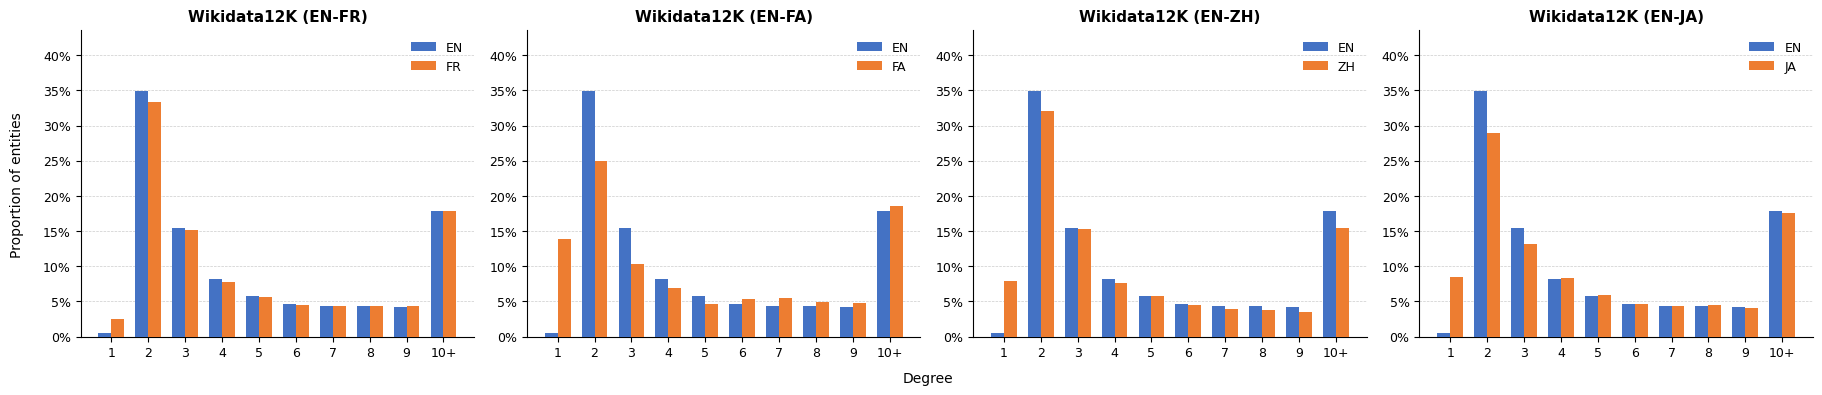

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from collections import defaultdict

# ── CONFIG ────────────────────────────────────────────────────────────────────
DATA_ROOT = r"wikidata12k_crosslingual"   # <-- folder produced by the builder script
PAIRS     = ["en_fr", "en_fa", "en_zh", "en_ja"]
TITLES    = {
    "en_fr": "Wikidata12K (EN-FR)",
    "en_fa": "Wikidata12K (EN-FA)",
    "en_zh": "Wikidata12K (EN-ZH)",
    "en_ja": "Wikidata12K (EN-JA)",
}
MAX_DEGREE_SHOWN = 10           # degrees 1-9 shown individually, 10+ grouped
# ─────────────────────────────────────────────────────────────────────────────


def load_edges(filepath):
    """
    Read a quadruples_{lang}.tsv file produced by the cross-lingual TKG builder.
    Expected columns (tab-separated, with header): head_id, rel_id, tail_id, begin, end
    Returns list of (head_id, tail_id) pairs.
    """
    df = pd.read_csv(filepath, sep="\t")
    return list(zip(df["head_id"].tolist(), df["tail_id"].tolist()))


def compute_degree_distribution(edges, max_shown=10):
    """
    Returns a dict: degree_bucket -> fraction_of_nodes (as percentage).
    Buckets are 1, 2, ..., max_shown-1, and max_shown (meaning >= max_shown).
    """
    degree = defaultdict(int)
    for h, t in edges:
        degree[h] += 1
        degree[t] += 1

    counts = defaultdict(int)
    for d in degree.values():
        bucket = d if d < max_shown else max_shown
        counts[bucket] += 1

    total = sum(counts.values())
    distribution = {}
    for b in range(1, max_shown + 1):
        distribution[b] = (counts.get(b, 0) / total) * 100 if total else 0.0
    return distribution


def plot_degree_distributions(data_root, pairs, titles, max_shown=10):
    n_pairs = len(pairs)
    fig, axes = plt.subplots(1, n_pairs, figsize=(4.5 * n_pairs, 3.8))

    if n_pairs == 1:
        axes = [axes]

    x     = np.arange(1, max_shown + 1)
    width = 0.35

    # Colors matching the reference image (blue for KG1, orange for KG2)
    color1 = "#4472C4"   # blue   – EN
    color2 = "#ED7D31"   # orange – other language

    for ax, pair in zip(axes, pairs):
        lang1, lang2 = pair.split("_")   # e.g. "en", "fr"

        triples1_path = os.path.join(data_root, pair, f"quadruples_{lang1}.tsv")
        triples2_path = os.path.join(data_root, pair, f"quadruples_{lang2}.tsv")

        edges1 = load_edges(triples1_path)
        edges2 = load_edges(triples2_path)

        dist1 = compute_degree_distribution(edges1, max_shown)
        dist2 = compute_degree_distribution(edges2, max_shown)

        vals1 = [dist1[b] for b in range(1, max_shown + 1)]
        vals2 = [dist2[b] for b in range(1, max_shown + 1)]

        ax.bar(x - width / 2, vals1, width,
               label=lang1.upper(), color=color1, zorder=3)
        ax.bar(x + width / 2, vals2, width,
               label=lang2.upper(), color=color2, zorder=3)

        # x-axis labels: 1-9 as numbers, last bucket as "10+"
        x_labels = [str(i) for i in range(1, max_shown)] + [f"{max_shown}+"]
        ax.set_xticks(x)
        ax.set_xticklabels(x_labels, fontsize=9)

        # y-axis as percentage
        ax.yaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
        ax.set_ylim(0, max(max(vals1), max(vals2)) * 1.25)
        ax.tick_params(axis="y", labelsize=9)

        # Light horizontal gridlines
        ax.yaxis.grid(True, linestyle="--", linewidth=0.5,
                      color="#cccccc", zorder=0)
        ax.set_axisbelow(True)

        # Remove top/right spines for cleaner look
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

        ax.set_title(titles[pair], fontsize=11, fontweight="bold", pad=6)
        ax.legend(fontsize=9, frameon=False)

    fig.text(0.5, -0.02, "Degree", ha="center", fontsize=10)
    fig.text(-0.01, 0.5, "Proportion of entities",
             va="center", rotation="vertical", fontsize=10)

    plt.tight_layout()
    plt.savefig("degree_distribution.png", dpi=150,
                bbox_inches="tight", facecolor="white")
    print("Saved -> degree_distribution.png")


if __name__ == "__main__":
    plot_degree_distributions(DATA_ROOT, PAIRS, TITLES, MAX_DEGREE_SHOWN)

Aggregating over 5 language KGs: ['en', 'fr', 'fa', 'zh', 'ja']
Note: 9160 facts before 1900 excluded from the plot (pre-1900 tail; per language: {'en': 2580, 'fr': 2483, 'fa': 821, 'zh': 2058, 'ja': 1218})
Saved -> edge_time_distribution_aggregate.png


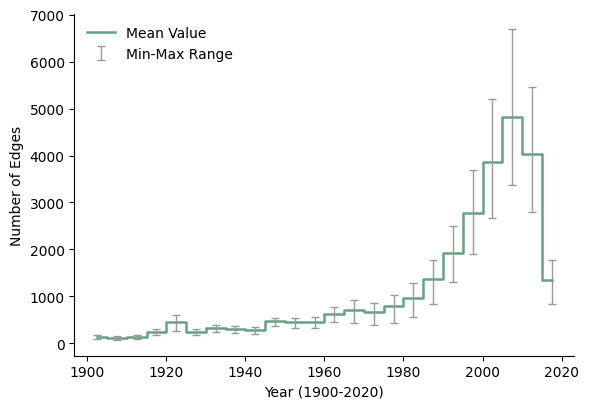

In [3]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ── CONFIG ────────────────────────────────────────────────────────────────────
DATA_ROOT = r"wikidata12k_crosslingual"   # <-- folder produced by the builder script
PAIRS     = ["en_fr", "en_fa", "en_zh", "en_ja"]

BIN_START = 1900     # facts before this year are dropped (see note below)
BIN_WIDTH = 5         # years per bin, matches the reference plot
# BIN_END is derived automatically from the data's max year, rounded up.
# ─────────────────────────────────────────────────────────────────────────────


def parse_year(s):
    y = s.split("-")[0]
    return None if y == "####" else int(y)


def load_begin_years(filepath):
    df = pd.read_csv(filepath, sep="\t", dtype={"begin": str})
    return df["begin"].apply(parse_year).dropna().astype(int).tolist()


def discover_language_files(data_root, pairs):
    """
    Collects one file per distinct language KG. 'en' is identical across all
    pairs (same entity filter regardless of the second language), so it's
    only loaded once; each pair contributes its non-English side.
    """
    files = {}
    lang1, lang2 = pairs[0].split("_")
    files[lang1] = os.path.join(data_root, pairs[0], f"quadruples_{lang1}.tsv")
    for pair in pairs:
        _, other_lang = pair.split("_")
        files[other_lang] = os.path.join(data_root, pair, f"quadruples_{other_lang}.tsv")
    return files


def compute_binned_counts(years, bin_edges):
    counts, _ = np.histogram(years, bins=bin_edges)
    return counts


def plot_aggregate_edge_time_distribution(data_root, pairs, bin_start=1900, bin_width=5):
    lang_files = discover_language_files(data_root, pairs)
    print(f"Aggregating over {len(lang_files)} language KGs: {list(lang_files.keys())}")

    lang_years = {lang: load_begin_years(path) for lang, path in lang_files.items()}

    max_year = max(max(y) for y in lang_years.values() if y)
    bin_end = int(np.ceil((max_year + 1) / bin_width) * bin_width)
    bin_edges = np.arange(bin_start, bin_end + bin_width, bin_width)

    dropped = {lang: sum(1 for y in years if y < bin_start) for lang, years in lang_years.items()}
    total_dropped = sum(dropped.values())
    if total_dropped:
        print(f"Note: {total_dropped} facts before {bin_start} excluded from the plot "
              f"(pre-{bin_start} tail; per language: {dropped})")

    # Per-language binned counts -> matrix [n_langs, n_bins]
    counts_matrix = np.array([
        compute_binned_counts(years, bin_edges) for years in lang_years.values()
    ])

    mean_counts = counts_matrix.mean(axis=0)
    min_counts  = counts_matrix.min(axis=0)
    max_counts  = counts_matrix.max(axis=0)

    bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2   # real calendar years

    fig, ax = plt.subplots(figsize=(6, 4.2))

    ax.step(bin_centers, mean_counts, where="mid",
            color="#66A182", linewidth=1.8, label="Mean Value")

    yerr_lower = mean_counts - min_counts
    yerr_upper = max_counts - mean_counts
    ax.errorbar(bin_centers, mean_counts, yerr=[yerr_lower, yerr_upper],
                fmt="none", ecolor="#999999", elinewidth=1, capsize=3,
                label="Min-Max Range")

    ax.set_xlabel(f"Year ({bin_start}-{bin_end})")
    ax.set_ylabel("Number of Edges")
    ax.legend(frameon=False, loc="upper left")

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    plt.tight_layout()
    plt.savefig("edge_time_distribution_aggregate.png", dpi=150,
                bbox_inches="tight", facecolor="white")
    print("Saved -> edge_time_distribution_aggregate.png")


if __name__ == "__main__":
    plot_aggregate_edge_time_distribution(DATA_ROOT, PAIRS, BIN_START, BIN_WIDTH)

# tkgl-wikidata

In [ ]:
import requests
import time
import pandas as pd
import json
import os
from collections import defaultdict
from itertools import combinations
from concurrent.futures import ThreadPoolExecutor, as_completed
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry

# -----------------------------
# Paths
# -----------------------------
FILE_PATH = "TKG/tkgl-wikidata_edgelist.csv"
SAVE_PATH = "tkgl_labels.tsv"
CHECKPOINT_PATH = "tkgl_labels_checkpoint.jsonl"   # append-only, safe to resume from
FAILED_PATH = "tkgl_labels_failed_batches.txt"

MAX_WORKERS = 8          # concurrent requests; polite for anonymous Wikidata API
BATCH_SIZE = 50          # API hard limit without apihighlimits

# -----------------------------
# Load CSV
# -----------------------------
df = pd.read_csv(FILE_PATH)
qids = sorted(set(df["head"]).union(set(df["tail"])))
print(f"Total entities: {len(qids)}")

# -----------------------------
# Resume support: skip QIDs we already have
# -----------------------------
done_qids = set()
if os.path.exists(CHECKPOINT_PATH):
    with open(CHECKPOINT_PATH, "r", encoding="utf-8") as f:
        for line in f:
            try:
                rec = json.loads(line)
                done_qids.add(rec["entity"])
            except Exception:
                continue
    print(f"Resuming: {len(done_qids)} entities already fetched")

remaining = [q for q in qids if q not in done_qids]
print(f"Remaining to fetch: {len(remaining)}")

batches = [remaining[i:i + BATCH_SIZE] for i in range(0, len(remaining), BATCH_SIZE)]

# -----------------------------
# Session with connection pooling + auto-retry
# -----------------------------
session = requests.Session()
retry = Retry(
    total=5,
    backoff_factor=1.5,               # 1.5s, 3s, 6s, 12s, 24s
    status_forcelist=[429, 500, 502, 503, 504],
    respect_retry_after_header=True,
)
adapter = HTTPAdapter(pool_connections=MAX_WORKERS, pool_maxsize=MAX_WORKERS, max_retries=retry)
session.mount("https://", adapter)
session.headers.update({"User-Agent": "CrossLingualTKG/1.0 (PhD research; contact: you@example.com)"})

def fetch_batch(batch):
    url = "https://www.wikidata.org/w/api.php"
    params = {
        "action": "wbgetentities",
        "ids": "|".join(batch),
        "props": "labels",
        "format": "json",
        "maxlag": 5,   # be a polite client; API will 200 with an error field if lagged, our retry logic handles it via status codes
    }
    try:
        r = session.get(url, params=params, timeout=30)
        r.raise_for_status()
        data = r.json()
        if "entities" not in data:
            return batch, None, data  # e.g. {"error": {...}} from maxlag
        return batch, data["entities"], None
    except Exception as e:
        return batch, None, str(e)

# -----------------------------
# Run concurrently, checkpoint as we go
# -----------------------------
checkpoint_f = open(CHECKPOINT_PATH, "a", encoding="utf-8")
failed_f = open(FAILED_PATH, "a", encoding="utf-8")

completed = 0
with ThreadPoolExecutor(max_workers=MAX_WORKERS) as executor:
    futures = {executor.submit(fetch_batch, b): b for b in batches}
    for future in as_completed(futures):
        batch, entities, error = future.result()
        if entities is None:
            failed_f.write(f"{','.join(batch)}\t{error}\n")
            failed_f.flush()
            continue
        for qid, data in entities.items():
            labels = {lang: info["value"] for lang, info in data.get("labels", {}).items()}
            checkpoint_f.write(json.dumps({"entity": qid, "labels": labels}) + "\n")
        checkpoint_f.flush()
        completed += len(batch)
        if completed % 2000 < BATCH_SIZE:
            print(f"{completed}/{len(remaining)}", end="\r")

checkpoint_f.close()
failed_f.close()
print("\nFetch pass complete. Check tkgl_labels_failed_batches.txt for any batches to retry.")

# -----------------------------
# Rebuild all_labels from checkpoint file (source of truth)
# -----------------------------
all_labels = {}
with open(CHECKPOINT_PATH, "r", encoding="utf-8") as f:
    for line in f:
        rec = json.loads(line)
        all_labels[rec["entity"]] = rec["labels"]

# -----------------------------
# Save labels (long format, as before)
# -----------------------------
label_df = pd.DataFrame([
    {"entity": qid, "lang": lang, "label": label}
    for qid, labels in all_labels.items()
    for lang, label in labels.items()
])
label_df.to_csv(SAVE_PATH, sep="\t", index=False)
print(f"Labels saved to {SAVE_PATH}")

# -----------------------------
# Coverage
# -----------------------------
lang_entity_count = defaultdict(int)
for labels in all_labels.values():
    for lang in labels:
        lang_entity_count[lang] += 1

df_cov = pd.DataFrame([
    {"lang": lang, "entities": count, "coverage_%": round(count / len(qids) * 100, 1)}
    for lang, count in lang_entity_count.items()
]).sort_values("entities", ascending=False)

print("\nTop 20 languages by coverage:")
print(df_cov.head(20).to_string(index=False))

# -----------------------------
# Pairwise overlap
# -----------------------------
TOP_N = 15
top_langs = df_cov.head(TOP_N)["lang"].tolist()
lang_entities = {
    lang: {qid for qid, labels in all_labels.items() if lang in labels}
    for lang in top_langs
}

print(f"\n{'LangA':6s} {'LangB':6s} {'|A∩B|':>8s} {'KG_A edges':>12s} {'KG_B edges':>12s} {'viable?':>8s}")
for lang_a, lang_b in combinations(top_langs, 2):
    ents_a = lang_entities[lang_a]
    ents_b = lang_entities[lang_b]
    overlap = ents_a & ents_b
    mask_a = df["head"].isin(ents_a) & df["tail"].isin(ents_a)
    mask_b = df["head"].isin(ents_b) & df["tail"].isin(ents_b)
    qa = mask_a.sum()
    qb = mask_b.sum()
    viable = "✅" if len(overlap) >= 1000 and qa >= 5000 and qb >= 5000 else "⚠️"
    print(f"{lang_a:6s} {lang_b:6s} {len(overlap):>8,} {qa:>12,} {qb:>12,} {viable:>8s}")

Total entities: 1226440
Remaining to fetch: 1226440


In [1]:
"""
Language coverage & pairwise overlap analysis for tkgl-wikidata.

Purpose:
    Decide which pair of languages to use for a cross-lingual TKG split,
    by measuring (on the ACTUAL entity set in your edgelist):
      1. how many entities have a label in each candidate language
      2. how many entities overlap between each pair of languages
      3. how many edges each resulting per-language KG would have

Design goals vs. the original per-entity REST approach:
    - Language codes are static reference data -> hardcoded once, no lookup per run.
    - Coverage/overlap queries go to Wikidata's SPARQL endpoint (WDQS), which can
      aggregate over thousands of entities server-side in a single request,
      instead of one REST call per 50 entities.
    - Only the ~20-25 candidate languages are ever requested (not all ~300
      languages Wikidata might have per entity), which keeps each response small.
    - Progress is checkpointed to disk so a stopped run can resume without
      re-fetching chunks already completed.

Usage:
    python language_coverage.py
Outputs:
    entity_lang_presence.csv     (entity, lang) pairs actually found
    lang_coverage.csv            per-language coverage over your entity set
    lang_pair_overlap.csv        pairwise overlap + viability for all candidate pairs
"""

import os
import json
import time
import requests
import pandas as pd
from itertools import combinations
from concurrent.futures import ThreadPoolExecutor, as_completed

# ============================================================
# CONFIG
# ============================================================
FILE_PATH = "TKG/tkgl-wikidata_edgelist.csv"   # <-- point at your real edgelist

CHUNK_SIZE = 3000          # entities per SPARQL query (VALUES clause)
MAX_WORKERS = 4            # keep modest; WDQS asks clients not to hammer it
ENDPOINT = "https://query.wikidata.org/sparql"

CHECKPOINT_PATH = "lang_presence_checkpoint.jsonl"   # resumable progress
OUT_PRESENCE = "entity_lang_presence.csv"
OUT_COVERAGE = "lang_coverage.csv"
OUT_OVERLAP = "lang_pair_overlap.csv"

# Viability thresholds for the pairwise report (tune as needed)
MIN_OVERLAP_ENTITIES = 1000
MIN_EDGES_PER_KG = 5000

HEADERS = {
    "User-Agent": "CrossLingualTKG/1.0 (PhD research; contact: you@example.com)",
    "Accept": "application/sparql-results+json",
}

# ============================================================
# STATIC LANGUAGE CODE TABLE
# ------------------------------------------------------------
# These are the actual Wikidata/Wikipedia language codes (mostly ISO 639-1,
# with a few ISO 639-3 codes for languages lacking a 639-1 code, e.g. arz,
# ceb, war). This is static reference data -- cache it, don't re-derive it
# every run. Seeded from the top article-count Wikipedias.
# ============================================================
WIKIDATA_LANG_CODES = {
    "en":  "English",
    "ceb": "Cebuano",
    "de":  "German",
    "fr":  "French",
    "sv":  "Swedish",
    "nl":  "Dutch",
    "es":  "Spanish",
    "ru":  "Russian",
    "it":  "Italian",
    "pl":  "Polish",
    "arz": "Egyptian Arabic",
    "zh":  "Chinese",
    "ja":  "Japanese",
    "uk":  "Ukrainian",
    "ar":  "Arabic",
    "vi":  "Vietnamese",
    "war": "Waray",
    "pt":  "Portuguese",
    "fa":  "Persian",
    "ce":  "Chechen",
    "ca":  "Catalan",
    "id":  "Indonesian",
    "ko":  "Korean",
    "tt":  "Tatar",
    "sr":  "Serbian",
}

TOP_N_LANGS = 20
TOP_LANGS = list(WIKIDATA_LANG_CODES.keys())[:TOP_N_LANGS]


def refresh_lang_codes_from_meta(save_path="wikipedia_language_codes.csv"):
    """
    OPTIONAL, run manually / once in a while -- NOT called automatically.
    Pulls the authoritative, auto-updated language/article-count table from
    Meta-Wiki and saves it locally so you never need to hit the network for
    this again. Use this only if you want to refresh or expand the static
    table above; the main analysis below does not require it.
    """
    tables = pd.read_html("https://meta.wikimedia.org/wiki/List_of_Wikipedias")
    # The exact table index can shift if the page layout changes -- inspect
    # `tables` if this breaks, and adjust the index accordingly.
    wiki_table = tables[1]
    wiki_table.to_csv(save_path, index=False)
    print(f"Saved language reference table to {save_path}")
    return wiki_table


# ============================================================
# STEP 1: Load entities from your edgelist
# ============================================================
def load_entities(file_path):
    df = pd.read_csv(file_path)
    qids = sorted(set(df["head"]).union(set(df["tail"])))
    print(f"Loaded edgelist: {len(df)} quadruples, {len(qids)} unique entities")
    return df, qids


# ============================================================
# STEP 2: SPARQL bulk presence check, chunked + checkpointed
# ============================================================
def build_query(chunk, langs):
    values = " ".join(f"wd:{q}" for q in chunk)
    lang_list = ", ".join(f"'{l}'" for l in langs)
    return f"""
    SELECT ?entity ?lang WHERE {{
      VALUES ?entity {{ {values} }}
      ?entity rdfs:label ?label .
      BIND(LANG(?label) AS ?lang)
      FILTER(?lang IN ({lang_list}))
    }}
    """


def fetch_chunk(chunk_id, chunk, langs):
    query = build_query(chunk, langs)
    for attempt in range(3):
        try:
            r = requests.post(
                ENDPOINT,
                data={"query": query, "format": "json"},
                headers=HEADERS,
                timeout=60,
            )
            r.raise_for_status()
            data = r.json()
            pairs = []
            for b in data["results"]["bindings"]:
                entity_uri = b["entity"]["value"]
                qid = entity_uri.rsplit("/", 1)[-1]
                lang = b["lang"]["value"]
                pairs.append((qid, lang))
            return chunk_id, pairs, None
        except Exception as e:
            wait = 5 * (attempt + 1)
            time.sleep(wait)
    return chunk_id, [], "failed after retries"


def fetch_presence(qids, langs, chunk_size=CHUNK_SIZE, max_workers=MAX_WORKERS,
                    checkpoint_path=CHECKPOINT_PATH):
    chunks = [qids[i:i + chunk_size] for i in range(0, len(qids), chunk_size)]
    print(f"{len(chunks)} chunks of up to {chunk_size} entities each")

    # Resume support: figure out which chunk_ids are already done.
    done_chunk_ids = set()
    if os.path.exists(checkpoint_path):
        with open(checkpoint_path, "r", encoding="utf-8") as f:
            for line in f:
                try:
                    rec = json.loads(line)
                    done_chunk_ids.add(rec["chunk_id"])
                except Exception:
                    continue
        print(f"Resuming: {len(done_chunk_ids)} chunks already fetched")

    pending = [(i, c) for i, c in enumerate(chunks) if i not in done_chunk_ids]
    print(f"Remaining chunks to fetch: {len(pending)}")

    ckpt_f = open(checkpoint_path, "a", encoding="utf-8")
    failed = []
    completed = 0

    if pending:
        with ThreadPoolExecutor(max_workers=max_workers) as ex:
            futures = {
                ex.submit(fetch_chunk, cid, chunk, langs): cid
                for cid, chunk in pending
            }
            for fut in as_completed(futures):
                chunk_id, pairs, err = fut.result()
                if err:
                    failed.append(chunk_id)
                else:
                    ckpt_f.write(json.dumps({"chunk_id": chunk_id, "pairs": pairs}) + "\n")
                    ckpt_f.flush()
                completed += 1
                print(f"{completed}/{len(pending)} chunks", end="\r")
    ckpt_f.close()

    if failed:
        print(f"\n{len(failed)} chunks failed after retries: {failed}")
        print("Re-run the script to retry only the missing chunks (resume is automatic).")

    # Rebuild full presence list from checkpoint file (source of truth).
    all_pairs = []
    with open(checkpoint_path, "r", encoding="utf-8") as f:
        for line in f:
            rec = json.loads(line)
            all_pairs.extend(rec["pairs"])

    presence_df = pd.DataFrame(all_pairs, columns=["entity", "lang"]).drop_duplicates()
    return presence_df


# ============================================================
# STEP 3: Coverage + pairwise overlap report
# ============================================================
def compute_coverage(presence_df, total_entities):
    cov = (
        presence_df.groupby("lang")["entity"].nunique()
        .rename("entities").reset_index()
    )
    cov["coverage_%"] = (cov["entities"] / total_entities * 100).round(1)
    cov = cov.sort_values("entities", ascending=False)
    return cov


def compute_pairwise_overlap(df, presence_df, langs,
                              min_overlap=MIN_OVERLAP_ENTITIES,
                              min_edges=MIN_EDGES_PER_KG):
    lang_entities = {
        lang: set(presence_df.loc[presence_df["lang"] == lang, "entity"])
        for lang in langs
    }

    rows = []
    for lang_a, lang_b in combinations(langs, 2):
        ents_a = lang_entities.get(lang_a, set())
        ents_b = lang_entities.get(lang_b, set())
        overlap = ents_a & ents_b

        mask_a = df["head"].isin(ents_a) & df["tail"].isin(ents_a)
        mask_b = df["head"].isin(ents_b) & df["tail"].isin(ents_b)
        qa, qb = int(mask_a.sum()), int(mask_b.sum())

        viable = len(overlap) >= min_overlap and qa >= min_edges and qb >= min_edges
        rows.append({
            "lang_a": lang_a,
            "lang_b": lang_b,
            "overlap_entities": len(overlap),
            "kg_a_edges": qa,
            "kg_b_edges": qb,
            "viable": viable,
        })

    overlap_df = pd.DataFrame(rows).sort_values("overlap_entities", ascending=False)
    return overlap_df


# ============================================================
# MAIN
# ============================================================
def main():
    df, qids = load_entities(FILE_PATH)

    print(f"\nCandidate languages ({len(TOP_LANGS)}): {TOP_LANGS}\n")

    presence_df = fetch_presence(qids, TOP_LANGS)
    presence_df.to_csv(OUT_PRESENCE, index=False)
    print(f"\nSaved raw presence pairs to {OUT_PRESENCE} ({len(presence_df)} rows)")

    cov = compute_coverage(presence_df, len(qids))
    cov.to_csv(OUT_COVERAGE, index=False)
    print(f"\nCoverage among candidate languages (saved to {OUT_COVERAGE}):")
    print(cov.to_string(index=False))

    overlap_df = compute_pairwise_overlap(df, presence_df, TOP_LANGS)
    overlap_df.to_csv(OUT_OVERLAP, index=False)
    print(f"\nPairwise overlap / viability (saved to {OUT_OVERLAP}):")
    print(overlap_df.to_string(index=False))

    viable = overlap_df[overlap_df["viable"]]
    print(f"\n{len(viable)} viable pairs out of {len(overlap_df)} checked.")
    if len(viable):
        print("Top candidates:")
        print(viable.head(10).to_string(index=False))


if __name__ == "__main__":
    main()

Loaded edgelist: 9856203 quadruples, 1226440 unique entities

Candidate languages (20): ['en', 'ceb', 'de', 'fr', 'sv', 'nl', 'es', 'ru', 'it', 'pl', 'arz', 'zh', 'ja', 'uk', 'ar', 'vi', 'war', 'pt', 'fa', 'ce']

409 chunks of up to 3000 entities each
Resuming: 404 chunks already fetched
Remaining chunks to fetch: 5
5/5 chunks
Saved raw presence pairs to entity_lang_presence.csv (5849748 rows)

Coverage among candidate languages (saved to lang_coverage.csv):
lang  entities  coverage_%
  en   1015523        82.8
  nl    707014        57.6
  es    582230        47.5
  fr    561413        45.8
  de    493365        40.2
  it    391510        31.9
  sv    306779        25.0
  pt    295991        24.1
  ru    231557        18.9
  pl    211109        17.2
  ja    179442        14.6
  zh    168899        13.8
 arz    167506        13.7
  ar    157490        12.8
  uk    122674        10.0
  fa    113890         9.3
  vi     70579         5.8
 ceb     31848         2.6
 war     20550         1

# create cross-lingual TKG from tkgl-wikidata

In [4]:
import os
import time
import requests
import pandas as pd
import numpy as np
from collections import defaultdict

# ============================================================
# CONFIG
# ============================================================
EDGELIST_PATH = r"C:\Users\Partiran\Desktop\TKG\tkgl-wikidata_edgelist.csv"   
OUTPUT_DIR    = "tkgl_wikidata_crosslingual"
LABELS_CACHE  = "tkgl_wikidata_labels.tsv"

LANG_PAIRS = [
    ("en", "fr"),
    ("en", "fa"),
    ("en", "zh"),
    ("en", "ja"),
]

RANDOM_SEED = 42
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Extend as needed -- unlisted relation codes just fall back to their own P-id.
RELATION_LABELS = {
    "P6":    "head of government",      "P17":   "country",
    "P26":   "spouse",                  "P27":   "country of citizenship",
    "P31":   "instance of",             "P39":   "position held",
    "P54":   "member of sports team",   "P69":   "educated at",
    "P102":  "member of political party","P108":  "employer",
    "P131":  "located in administrative entity",
    "P150":  "contains administrative territorial entity",
    "P166":  "award received",          "P190":  "twinned administrative body",
    "P463":  "member of",               "P512":  "academic degree",
    "P551":  "residence",               "P579":  "IPC sports discipline code",
    "P793":  "significant event",       "P937":  "work location",
    "P1346": "winner",                  "P1376": "capital of",
    "P1411": "nominated for",           "P1433": "published in",
    "P1435": "heritage designation",    "P2348": "time period",
    "P2962": "title of chess person",
}

NEEDED_LANGS = sorted({lang for pair in LANG_PAIRS for lang in pair} | {"en"})

SPARQL_ENDPOINT = "https://query.wikidata.org/sparql"
CHUNK_SIZE = 3000
MAX_RETRIES = 3
HEADERS = {
    "User-Agent": "CrossLingualTKG/1.0 (PhD research; contact: you@example.com)",
    "Accept": "application/sparql-results+json",
}

# ============================================================
# Step 1: Load edgelist
# ------------------------------------------------------------
# Uses explicit dtypes to keep memory down on a large file. If the file is
# too large to fit in memory at all (many millions of rows), switch this to
# chunked reading with pd.read_csv(..., chunksize=...) and accumulate unique
# entities/relations across chunks instead of loading everything at once --
# ask if you hit that point and want the chunked version.
# ============================================================
print("Step 1: Loading edgelist...")
df_quad = pd.read_csv(
    EDGELIST_PATH,
    dtype={"ts": "int64", "head": "string", "tail": "string", "relation_type": "string"},
)
all_qids = sorted(set(df_quad["head"]).union(set(df_quad["tail"])))
print(f"  {len(df_quad):,} quadruples | {len(all_qids):,} unique entities")

if len(all_qids) > 300_000:
    print(f"  NOTE: {len(all_qids):,} entities is large enough that even bulk SPARQL "
          f"fetching may take a while ({len(all_qids)//CHUNK_SIZE:,}+ requests). "
          f"If this becomes impractical, the Wikidata JSON dump + local filtering "
          f"approach avoids the API entirely -- ask if you want that version.")

# ============================================================
# Step 2: Fetch multilingual labels via bulk SPARQL, incrementally cached
# ============================================================
def build_query(chunk, langs):
    values = " ".join(f"wd:{q}" for q in chunk)
    lang_list = ", ".join(f"'{l}'" for l in langs)
    return f"""
    SELECT ?entity ?lang ?label WHERE {{
      VALUES ?entity {{ {values} }}
      ?entity rdfs:label ?label .
      BIND(LANG(?label) AS ?lang)
      FILTER(?lang IN ({lang_list}))
    }}
    """

def fetch_chunk(chunk, langs):
    query = build_query(chunk, langs)
    for attempt in range(MAX_RETRIES):
        try:
            r = requests.post(
                SPARQL_ENDPOINT,
                data={"query": query, "format": "json"},
                headers=HEADERS, timeout=60,
            )
            r.raise_for_status()
            data = r.json()
            rows = []
            for b in data["results"]["bindings"]:
                qid = b["entity"]["value"].rsplit("/", 1)[-1]
                rows.append((qid, b["lang"]["value"], b["label"]["value"]))
            return rows
        except Exception:
            time.sleep(5 * (attempt + 1))
    return []

print("\nStep 2: Fetching multilingual labels (incremental, SPARQL bulk)...")

if os.path.exists(LABELS_CACHE):
    df_labels = pd.read_csv(LABELS_CACHE, sep="\t")
    print(f"  Loaded existing cache: {len(df_labels):,} rows")
else:
    df_labels = pd.DataFrame(columns=["entity", "lang", "label"])
    print("  No existing cache found, starting fresh")

already_covered = set(df_labels["entity"])
missing_qids = [q for q in all_qids if q not in already_covered]
print(f"  Entities already cached: {len(already_covered):,}")
print(f"  Entities to fetch: {len(missing_qids):,}")

if missing_qids:
    chunks = [missing_qids[i:i + CHUNK_SIZE] for i in range(0, len(missing_qids), CHUNK_SIZE)]
    new_rows = []
    t_start = time.time()
    for i, chunk in enumerate(chunks):
        new_rows.extend(fetch_chunk(chunk, NEEDED_LANGS))
        done = min((i + 1) * CHUNK_SIZE, len(missing_qids))
        elapsed = time.time() - t_start
        print(f"  {done:,}/{len(missing_qids):,} entities queried "
              f"({elapsed:.0f}s elapsed)...", end="\r")

    if new_rows:
        df_new = pd.DataFrame(new_rows, columns=["entity", "lang", "label"])
        df_labels = pd.concat([df_labels, df_new], ignore_index=True).drop_duplicates()

    found_now = set(df_new["entity"]) if new_rows else set()
    truly_empty = set(missing_qids) - found_now
    if truly_empty:
        placeholder = pd.DataFrame(
            [{"entity": q, "lang": "en", "label": q} for q in truly_empty]
        )
        df_labels = pd.concat([df_labels, placeholder], ignore_index=True).drop_duplicates()

    df_labels.to_csv(LABELS_CACHE, sep="\t", index=False)
    print(f"\n  Done. Cache now has {len(df_labels):,} rows, "
          f"{df_labels['entity'].nunique():,} entities covered.")
else:
    print("  Nothing to fetch, cache already complete.")

# ============================================================
# Step 3: Build entity -> language set + label lookup
# ============================================================
print("\nStep 3: Building entity-language maps...")
entity_langs = df_labels.groupby("entity")["lang"].apply(set).to_dict()
label_lookup = df_labels.set_index(["entity", "lang"])["label"].to_dict()

def get_label(entity, lang):
    return label_lookup.get((entity, lang),
           label_lookup.get((entity, "en"), entity))

lang_counts = defaultdict(int)
for langs in entity_langs.values():
    for lang in langs:
        lang_counts[lang] += 1

print(f"  Entities with labels: {len(entity_langs):,}")
print(f"\n  Coverage for needed languages:")
for lang in NEEDED_LANGS:
    count = lang_counts.get(lang, 0)
    print(f"    {lang:5s}: {count:>8,} / {len(all_qids):,} ({100*count/len(all_qids):.1f}%)")

# ============================================================
# Step 4: Pairwise overlap diagnostic (sanity check before building)
# ============================================================
print(f"\nStep 4: Pairwise overlap check...")
print(f"\n{'Pair':8s} {'|KG_A|':>10s} {'|KG_B|':>10s} {'|Align|':>10s} "
      f"{'KG_A quads':>12s} {'KG_B quads':>12s}")

for lang_a, lang_b in LANG_PAIRS:
    ents_a = {e for e, ls in entity_langs.items() if lang_a in ls}
    ents_b = {e for e, ls in entity_langs.items() if lang_b in ls}
    both   = ents_a & ents_b
    qa = (df_quad["head"].isin(ents_a) & df_quad["tail"].isin(ents_a)).sum()
    qb = (df_quad["head"].isin(ents_b) & df_quad["tail"].isin(ents_b)).sum()
    print(f"{lang_a}-{lang_b:4s} {len(ents_a):>10,} {len(ents_b):>10,} "
          f"{len(both):>10,} {qa:>12,} {qb:>12,}")

# ============================================================
# Step 5: Build cross-lingual dataset for each pair
# ============================================================
print(f"\nStep 5: Building cross-lingual datasets...")
summary_rows = []
np.random.seed(RANDOM_SEED)

def to_ids_vectorized(df, ent2id, rel2id):
    h = df["head"].map(ent2id)
    t = df["tail"].map(ent2id)
    r = df["relation_type"].map(rel2id)
    keep = h.notna() & t.notna() & r.notna()
    return pd.DataFrame({
        "head_id": h[keep].astype(int).values,
        "rel_id":  r[keep].astype(int).values,
        "tail_id": t[keep].astype(int).values,
        "ts":      df.loc[keep, "ts"].values,
    })

for lang_a, lang_b in LANG_PAIRS:
    print(f"\n{'='*55}")
    print(f"Building {lang_a.upper()}-{lang_b.upper()}...")
    pair_dir = os.path.join(OUTPUT_DIR, f"{lang_a}_{lang_b}")
    os.makedirs(pair_dir, exist_ok=True)

    ents_a = {e for e, ls in entity_langs.items() if lang_a in ls}
    ents_b = {e for e, ls in entity_langs.items() if lang_b in ls}

    mask_a = df_quad["head"].isin(ents_a) & df_quad["tail"].isin(ents_a)
    mask_b = df_quad["head"].isin(ents_b) & df_quad["tail"].isin(ents_b)
    kg_a = df_quad[mask_a].copy().reset_index(drop=True)
    kg_b = df_quad[mask_b].copy().reset_index(drop=True)

    present_a = set(kg_a["head"]) | set(kg_a["tail"])
    present_b = set(kg_b["head"]) | set(kg_b["tail"])
    alignment_ents = sorted(present_a & present_b)   # ALL alignment links kept, none dropped

    print(f"  KG_{lang_a.upper()}: {len(present_a):,} entities | {len(kg_a):,} quadruples")
    print(f"  KG_{lang_b.upper()}: {len(present_b):,} entities | {len(kg_b):,} quadruples")
    print(f"  Alignment pairs:  {len(alignment_ents):,}")

    ent2id_a = {e: i for i, e in enumerate(sorted(present_a))}
    ent2id_b = {e: i for i, e in enumerate(sorted(present_b))}
    all_rels  = sorted(set(kg_a["relation_type"]) | set(kg_b["relation_type"]))
    rel2id    = {r: i for i, r in enumerate(all_rels)}

    pd.DataFrame([{
        "id": ent2id_a[e], "entity": e,
        f"label_{lang_a}": get_label(e, lang_a)
    } for e in sorted(present_a)]).to_csv(
        f"{pair_dir}/entity2id_{lang_a}.tsv", sep="\t", index=False)

    pd.DataFrame([{
        "id": ent2id_b[e], "entity": e,
        f"label_{lang_b}": get_label(e, lang_b)
    } for e in sorted(present_b)]).to_csv(
        f"{pair_dir}/entity2id_{lang_b}.tsv", sep="\t", index=False)

    pd.DataFrame([{
        "id": rel2id[r], "relation": r,
        "label_en": RELATION_LABELS.get(r, r)
    } for r in all_rels]).to_csv(
        f"{pair_dir}/relation2id.tsv", sep="\t", index=False)

    to_ids_vectorized(kg_a, ent2id_a, rel2id).to_csv(
        f"{pair_dir}/quadruples_{lang_a}.tsv", sep="\t", index=False)
    to_ids_vectorized(kg_b, ent2id_b, rel2id).to_csv(
        f"{pair_dir}/quadruples_{lang_b}.tsv", sep="\t", index=False)

    pd.DataFrame([{
        f"id_{lang_a}":    ent2id_a[e],
        f"id_{lang_b}":    ent2id_b[e],
        "entity":          e,
        f"label_{lang_a}": get_label(e, lang_a),
        f"label_{lang_b}": get_label(e, lang_b)
    } for e in alignment_ents]).to_csv(
        f"{pair_dir}/alignment_all.tsv", sep="\t", index=False)

    summary_rows.append({
        "pair":            f"{lang_a}-{lang_b}",
        "kg_a_entities":   len(present_a),
        "kg_b_entities":   len(present_b),
        "kg_a_quads":      len(kg_a),
        "kg_b_quads":      len(kg_b),
        "alignment_pairs": len(alignment_ents),
        "relations":       len(all_rels),
    })
    print(f"  Saved to {pair_dir}/")

# ============================================================
# Step 6: Summary
# ============================================================
df_summary = pd.DataFrame(summary_rows)
df_summary.to_csv(f"{OUTPUT_DIR}/dataset_summary.tsv", sep="\t", index=False)

print(f"\n\n{'='*55}")
print("FINAL SUMMARY")
print("="*55)
print(df_summary.to_string(index=False))
print(f"\nAll files saved under: {OUTPUT_DIR}")

Step 1: Loading edgelist...
  9,856,203 quadruples | 1,226,440 unique entities
  NOTE: 1,226,440 entities is large enough that even bulk SPARQL fetching may take a while (408+ requests). If this becomes impractical, the Wikidata JSON dump + local filtering approach avoids the API entirely -- ask if you want that version.

Step 2: Fetching multilingual labels (incremental, SPARQL bulk)...
  No existing cache found, starting fresh
  Entities already cached: 0
  Entities to fetch: 1,226,440
  1,226,440/1,226,440 entities queried (1047s elapsed)...
  Done. Cache now has 2,227,084 rows, 1,226,440 entities covered.

Step 3: Building entity-language maps...
  Entities with labels: 1,226,440

  Coverage for needed languages:
    en   : 1,203,413 / 1,226,440 (98.1%)
    fa   :  113,898 / 1,226,440 (9.3%)
    fr   :  561,415 / 1,226,440 (45.8%)
    ja   :  179,446 / 1,226,440 (14.6%)
    zh   :  168,912 / 1,226,440 (13.8%)

Step 4: Pairwise overlap check...

Pair         |KG_A|     |KG_B|    |Al

Saved -> degree_distribution.png


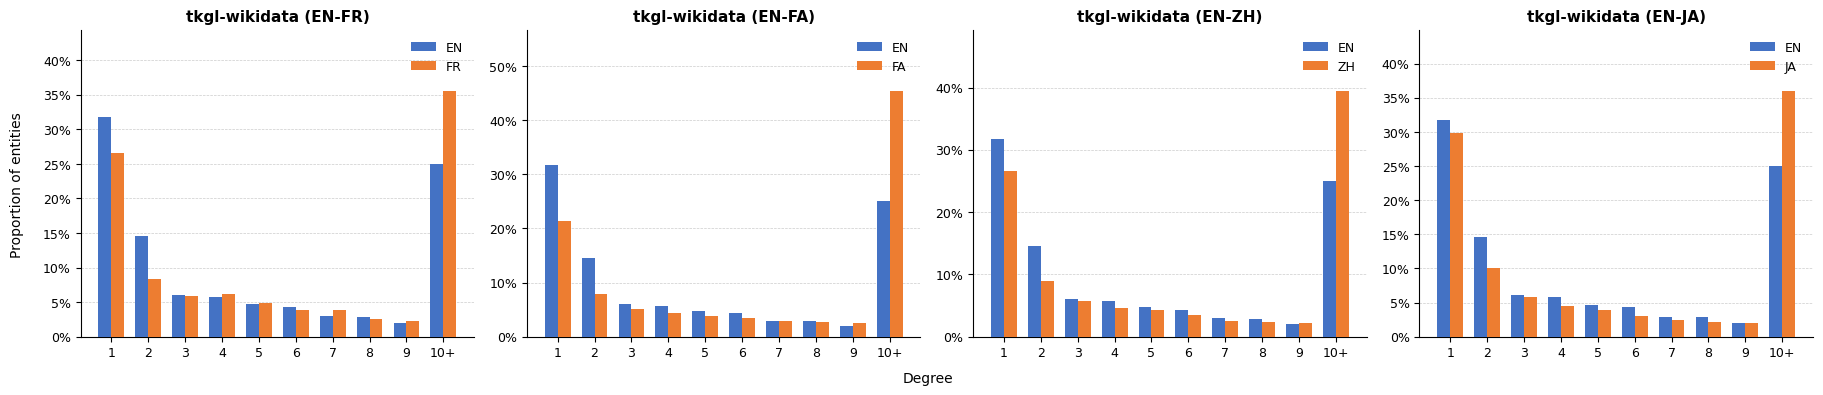

In [5]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from collections import defaultdict

# ── CONFIG ────────────────────────────────────────────────────────────────────
DATA_ROOT = r"tkgl_wikidata_crosslingual"   # <-- folder produced by the builder script
PAIRS     = ["en_fr", "en_fa", "en_zh", "en_ja"]
TITLES    = {
    "en_fr": "tkgl-wikidata (EN-FR)",
    "en_fa": "tkgl-wikidata (EN-FA)",
    "en_zh": "tkgl-wikidata (EN-ZH)",
    "en_ja": "tkgl-wikidata (EN-JA)",
}
MAX_DEGREE_SHOWN = 10           # degrees 1-9 shown individually, 10+ grouped
# ─────────────────────────────────────────────────────────────────────────────


def load_edges(filepath):
    """
    Read a quadruples_{lang}.tsv file produced by the cross-lingual TKG builder.
    Expected columns (tab-separated, with header): head_id, rel_id, tail_id, begin, end
    Returns list of (head_id, tail_id) pairs.
    """
    df = pd.read_csv(filepath, sep="\t")
    return list(zip(df["head_id"].tolist(), df["tail_id"].tolist()))


def compute_degree_distribution(edges, max_shown=10):
    """
    Returns a dict: degree_bucket -> fraction_of_nodes (as percentage).
    Buckets are 1, 2, ..., max_shown-1, and max_shown (meaning >= max_shown).
    """
    degree = defaultdict(int)
    for h, t in edges:
        degree[h] += 1
        degree[t] += 1

    counts = defaultdict(int)
    for d in degree.values():
        bucket = d if d < max_shown else max_shown
        counts[bucket] += 1

    total = sum(counts.values())
    distribution = {}
    for b in range(1, max_shown + 1):
        distribution[b] = (counts.get(b, 0) / total) * 100 if total else 0.0
    return distribution


def plot_degree_distributions(data_root, pairs, titles, max_shown=10):
    n_pairs = len(pairs)
    fig, axes = plt.subplots(1, n_pairs, figsize=(4.5 * n_pairs, 3.8))

    if n_pairs == 1:
        axes = [axes]

    x     = np.arange(1, max_shown + 1)
    width = 0.35

    # Colors matching the reference image (blue for KG1, orange for KG2)
    color1 = "#4472C4"   # blue   – EN
    color2 = "#ED7D31"   # orange – other language

    for ax, pair in zip(axes, pairs):
        lang1, lang2 = pair.split("_")   # e.g. "en", "fr"

        triples1_path = os.path.join(data_root, pair, f"quadruples_{lang1}.tsv")
        triples2_path = os.path.join(data_root, pair, f"quadruples_{lang2}.tsv")

        edges1 = load_edges(triples1_path)
        edges2 = load_edges(triples2_path)

        dist1 = compute_degree_distribution(edges1, max_shown)
        dist2 = compute_degree_distribution(edges2, max_shown)

        vals1 = [dist1[b] for b in range(1, max_shown + 1)]
        vals2 = [dist2[b] for b in range(1, max_shown + 1)]

        ax.bar(x - width / 2, vals1, width,
               label=lang1.upper(), color=color1, zorder=3)
        ax.bar(x + width / 2, vals2, width,
               label=lang2.upper(), color=color2, zorder=3)

        # x-axis labels: 1-9 as numbers, last bucket as "10+"
        x_labels = [str(i) for i in range(1, max_shown)] + [f"{max_shown}+"]
        ax.set_xticks(x)
        ax.set_xticklabels(x_labels, fontsize=9)

        # y-axis as percentage
        ax.yaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
        ax.set_ylim(0, max(max(vals1), max(vals2)) * 1.25)
        ax.tick_params(axis="y", labelsize=9)

        # Light horizontal gridlines
        ax.yaxis.grid(True, linestyle="--", linewidth=0.5,
                      color="#cccccc", zorder=0)
        ax.set_axisbelow(True)

        # Remove top/right spines for cleaner look
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

        ax.set_title(titles[pair], fontsize=11, fontweight="bold", pad=6)
        ax.legend(fontsize=9, frameon=False)

    fig.text(0.5, -0.02, "Degree", ha="center", fontsize=10)
    fig.text(-0.01, 0.5, "Proportion of entities",
             va="center", rotation="vertical", fontsize=10)

    plt.tight_layout()
    plt.savefig("degree_distribution.png", dpi=150,
                bbox_inches="tight", facecolor="white")
    print("Saved -> degree_distribution.png")


if __name__ == "__main__":
    plot_degree_distributions(DATA_ROOT, PAIRS, TITLES, MAX_DEGREE_SHOWN)

Aggregating over 5 language KGs: ['en', 'fr', 'fa', 'zh', 'ja']
Year range in data: 0-2024  |  binned as 0-2025
Saved -> tkgl_wikidata_time_distribution.png


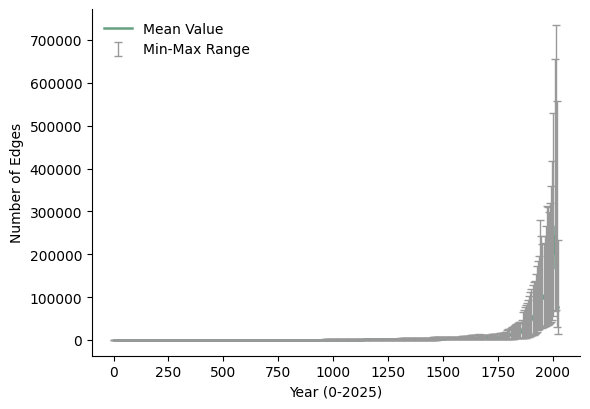

In [9]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# CONFIG
# ============================================================
DATA_ROOT = r"tkgl_wikidata_crosslingual"   # <-- folder produced by the builder script
PAIRS     = ["en_fr", "en_fa", "en_zh", "en_ja"]

# ------------------------------------------------------------
# CORRECTED ASSUMPTION (a previous version added +1900, which was wrong --
# it produced an axis running to year 3925 on real data, meaning raw ts
# values already reach ~2025 themselves). The evidence indicates 'ts' IS
# the real calendar year directly (with very old facts near ts=0/1
# representing ancient dates), not an offset from 1900. If your data turns
# out to use a different convention after checking the printed year range
# below, adjust ts_to_year accordingly.
# ------------------------------------------------------------
def ts_to_year(ts):
    return ts

BIN_WIDTH = 5   # years per bin, matches the reference plot
# ============================================================


def load_years(filepath):
    df = pd.read_csv(filepath, sep="\t")
    return ts_to_year(df["ts"]).astype(int).tolist()


def discover_language_files(data_root, pairs):
    files = {}
    lang1, _ = pairs[0].split("_")
    files[lang1] = os.path.join(data_root, pairs[0], f"quadruples_{lang1}.tsv")
    for pair in pairs:
        _, other_lang = pair.split("_")
        files[other_lang] = os.path.join(data_root, pair, f"quadruples_{other_lang}.tsv")
    return files


def compute_binned_counts(years, bin_edges):
    counts, _ = np.histogram(years, bins=bin_edges)
    return counts


def plot_aggregate_edge_time_distribution(data_root, pairs, bin_width=5):
    lang_files = discover_language_files(data_root, pairs)
    print(f"Aggregating over {len(lang_files)} language KGs: {list(lang_files.keys())}")

    lang_years = {lang: load_years(path) for lang, path in lang_files.items()}

    all_years_flat = [y for years in lang_years.values() for y in years]
    min_year = min(all_years_flat)
    max_year = max(all_years_flat)

    # bin_start is derived from the actual earliest year in the data
    # (rounded down to the nearest bin_width) -- not a hardcoded epoch.
    bin_start = int(np.floor(min_year / bin_width) * bin_width)
    bin_end   = int(np.ceil((max_year + 1) / bin_width) * bin_width)
    bin_edges = np.arange(bin_start, bin_end + bin_width, bin_width)

    print(f"Year range in data: {min_year}-{max_year}  |  binned as {bin_start}-{bin_end}")

    counts_matrix = np.array([
        compute_binned_counts(years, bin_edges) for years in lang_years.values()
    ])

    mean_counts = counts_matrix.mean(axis=0)
    min_counts  = counts_matrix.min(axis=0)
    max_counts  = counts_matrix.max(axis=0)

    bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2   # real calendar years

    fig, ax = plt.subplots(figsize=(6, 4.2))

    ax.step(bin_centers, mean_counts, where="mid",
            color="#66A182", linewidth=1.8, label="Mean Value")

    yerr_lower = mean_counts - min_counts
    yerr_upper = max_counts - mean_counts
    ax.errorbar(bin_centers, mean_counts, yerr=[yerr_lower, yerr_upper],
                fmt="none", ecolor="#999999", elinewidth=1, capsize=3,
                label="Min-Max Range")

    ax.set_xlabel(f"Year ({bin_start}-{bin_end})")
    ax.set_ylabel("Number of Edges")
    ax.legend(frameon=False, loc="upper left")

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    plt.tight_layout()
    plt.savefig("tkgl_wikidata_time_distribution.png", dpi=150,
                bbox_inches="tight", facecolor="white")
    print("Saved -> tkgl_wikidata_time_distribution.png")


if __name__ == "__main__":
    plot_aggregate_edge_time_distribution(DATA_ROOT, PAIRS, BIN_WIDTH)

Aggregating over 5 language KGs: ['en', 'fr', 'fa', 'zh', 'ja']
Dropped 5224333 facts before 1900 (ancient/outlier tail; set MIN_YEAR=None to disable)
Year range in data: 1900-2024  |  binned as 1900-2025
Saved -> tkgl_wikidata_time_distribution.png


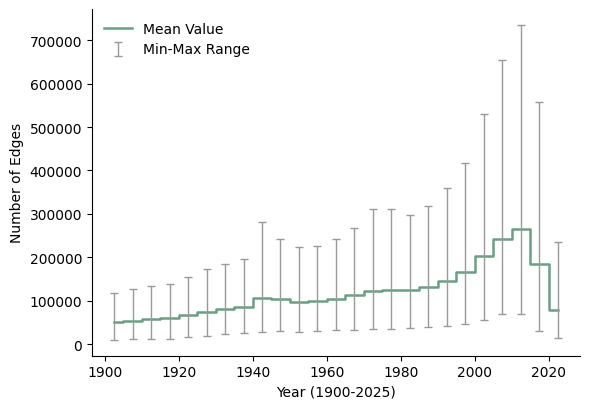

In [10]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# CONFIG
# ============================================================
DATA_ROOT = r"tkgl_wikidata_crosslingual"   # <-- folder produced by the builder script
PAIRS     = ["en_fr", "en_fa", "en_zh", "en_ja"]

# ------------------------------------------------------------
# CORRECTED ASSUMPTION (a previous version added +1900, which was wrong --
# it produced an axis running to year 3925 on real data, meaning raw ts
# values already reach ~2025 themselves). The evidence indicates 'ts' IS
# the real calendar year directly (with very old facts near ts=0/1
# representing ancient dates), not an offset from 1900. If your data turns
# out to use a different convention after checking the printed year range
# below, adjust ts_to_year accordingly.
# ------------------------------------------------------------
def ts_to_year(ts):
    return ts

BIN_WIDTH = 5   # years per bin, matches the reference plot

# A thin tail of very old facts (potentially misdated, or genuinely ancient
# one-off records) can stretch the axis so far that the real action --
# almost all the data -- gets compressed into a sliver at the right edge.
# Facts before MIN_YEAR are dropped from the plot (count reported below)
# rather than silently distorting the scale. Set to None to disable.
MIN_YEAR = 1900
# ============================================================


def load_years(filepath):
    df = pd.read_csv(filepath, sep="\t")
    return ts_to_year(df["ts"]).astype(int).tolist()


def discover_language_files(data_root, pairs):
    files = {}
    lang1, _ = pairs[0].split("_")
    files[lang1] = os.path.join(data_root, pairs[0], f"quadruples_{lang1}.tsv")
    for pair in pairs:
        _, other_lang = pair.split("_")
        files[other_lang] = os.path.join(data_root, pair, f"quadruples_{other_lang}.tsv")
    return files


def compute_binned_counts(years, bin_edges):
    counts, _ = np.histogram(years, bins=bin_edges)
    return counts


def plot_aggregate_edge_time_distribution(data_root, pairs, bin_width=5, min_year_cutoff=MIN_YEAR):
    lang_files = discover_language_files(data_root, pairs)
    print(f"Aggregating over {len(lang_files)} language KGs: {list(lang_files.keys())}")

    lang_years = {lang: load_years(path) for lang, path in lang_files.items()}

    if min_year_cutoff is not None:
        dropped_total = 0
        for lang, years in lang_years.items():
            before = len(years)
            lang_years[lang] = [y for y in years if y >= min_year_cutoff]
            dropped_total += before - len(lang_years[lang])
        if dropped_total:
            print(f"Dropped {dropped_total} facts before {min_year_cutoff} "
                  f"(ancient/outlier tail; set MIN_YEAR=None to disable)")

    all_years_flat = [y for years in lang_years.values() for y in years]
    if not all_years_flat:
        raise ValueError(
            f"No facts remain after applying MIN_YEAR={min_year_cutoff}. "
            f"Lower MIN_YEAR (or set it to None) and rerun."
        )
    min_year = min(all_years_flat)
    max_year = max(all_years_flat)

    # bin_start is derived from the actual earliest year in the data
    # (rounded down to the nearest bin_width) -- not a hardcoded epoch.
    bin_start = int(np.floor(min_year / bin_width) * bin_width)
    bin_end   = int(np.ceil((max_year + 1) / bin_width) * bin_width)
    bin_edges = np.arange(bin_start, bin_end + bin_width, bin_width)

    print(f"Year range in data: {min_year}-{max_year}  |  binned as {bin_start}-{bin_end}")

    counts_matrix = np.array([
        compute_binned_counts(years, bin_edges) for years in lang_years.values()
    ])

    mean_counts = counts_matrix.mean(axis=0)
    min_counts  = counts_matrix.min(axis=0)
    max_counts  = counts_matrix.max(axis=0)

    bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2   # real calendar years

    fig, ax = plt.subplots(figsize=(6, 4.2))

    ax.step(bin_centers, mean_counts, where="mid",
            color="#66A182", linewidth=1.8, label="Mean Value")

    yerr_lower = mean_counts - min_counts
    yerr_upper = max_counts - mean_counts
    ax.errorbar(bin_centers, mean_counts, yerr=[yerr_lower, yerr_upper],
                fmt="none", ecolor="#999999", elinewidth=1, capsize=3,
                label="Min-Max Range")

    ax.set_xlabel(f"Year ({bin_start}-{bin_end})")
    ax.set_ylabel("Number of Edges")
    ax.legend(frameon=False, loc="upper left")

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    plt.tight_layout()
    plt.savefig("tkgl_wikidata_time_distribution.png", dpi=150,
                bbox_inches="tight", facecolor="white")
    print("Saved -> tkgl_wikidata_time_distribution.png")


if __name__ == "__main__":
    plot_aggregate_edge_time_distribution(DATA_ROOT, PAIRS, BIN_WIDTH, MIN_YEAR)